# E5：エポック内の平均点で評価した SGD の可視化

`programs/analysis_e5.py` を呼び出し，揺らぎ（表IVと同じ定義）と予算での精度の表，SGD（最終点），SGD（平均点），ASA-SVRG の推移の図を作る．集計する設定は `SETTINGS` で選べる（既定は全設定）．

In [1]:
import os, sys
sys.path.insert(0, os.path.join(os.getcwd(), 'programs'))
import analysis_e5 as a
from IPython.display import Markdown, Image, display

# 集計する (データセット, バッチサイズ)．例：[('imagewoof', 128), ('cifar10', 128)]
SETTINGS = list(a.SETTINGS)

In [2]:
text = a.write_summary(SETTINGS)
display(Markdown(text))

# E5：エポック内の平均点で評価した SGD（集計結果）

値は5シードの平均 ± 標準誤差（表IVと同じく ddof=0）である．揺らぎは，$ \#\mathrm{grad}/N $ が予算の1/2以上・予算以下の区間における隣り合う評価点の間のテスト精度の変化 $ |a_{s} - a_{s-1}| $ の平均である（表IVと同じ定義）．SGD の評価点の間隔は1，ASA-SVRG は2である．SGD は1エポックおきに間引いて間隔を2にそろえた値も示す（ASA-SVRG は間隔2の列に示す）．ASA-SVRG と「SGD（表IVの既存ログ）」は，表IVの元の既存ログである．

## 揺らぎと予算での精度

| データセット | バッチサイズ | 予算 | 系列 | シード数 | 揺らぎ（間隔1）［%pt］ | 揺らぎ（間隔2）［%pt］ | 予算での精度［%］ | 予算での学習損失 |
|---|---:|---:|---|---:|---:|---:|---:|---:|
| ImageWoof | 128 | 200 | SGD（最終点） | 5 | 3.05 ± 0.16 | 2.76 ± 0.08 | 46.54 ± 0.89 | 3.1407 ± 0.0226 |
| ImageWoof | 128 | 200 | SGD（平均点） | 5 | 0.19 ± 0.01 | 0.21 ± 0.01 | 51.43 ± 0.18 | 3.0029 ± 0.0048 |
| ImageWoof | 128 | 200 | ASA-SVRG | 5 | — | 0.20 ± 0.01 | 45.81 ± 0.20 | 3.3843 ± 0.0043 |
| ImageWoof | 128 | 200 | SGD（表IVの既存ログ） | 5 | 3.05 ± 0.15 | 2.78 ± 0.07 | 46.65 ± 0.87 | 3.1396 ± 0.0225 |
| CIFAR-10 | 128 | 90 | SGD（最終点） | 5 | 0.34 ± 0.02 | 0.32 ± 0.03 | 76.24 ± 0.09 | 0.2332 ± 0.0000 |
| CIFAR-10 | 128 | 90 | SGD（平均点） | 5 | 0.05 ± 0.00 | 0.06 ± 0.00 | 76.25 ± 0.11 | 0.2332 ± 0.0000 |
| CIFAR-10 | 128 | 90 | ASA-SVRG | 5 | — | 0.22 ± 0.00 | 75.20 ± 0.15 | 0.3894 ± 0.0019 |
| CIFAR-10 | 128 | 90 | SGD（表IVの既存ログ） | 5 | 0.34 ± 0.02 | 0.32 ± 0.03 | 76.24 ± 0.09 | 0.2332 ± 0.0000 |
| CIFAR-10 | 512 | 350 | SGD（最終点） | 5 | 0.20 ± 0.01 | 0.19 ± 0.02 | 75.81 ± 0.07 | 0.2334 ± 0.0000 |
| CIFAR-10 | 512 | 350 | SGD（平均点） | 5 | 0.04 ± 0.00 | 0.04 ± 0.00 | 75.76 ± 0.07 | 0.2334 ± 0.0001 |
| CIFAR-10 | 512 | 350 | ASA-SVRG | 5 | — | 0.09 ± 0.01 | 75.10 ± 0.17 | 0.3760 ± 0.0056 |
| CIFAR-10 | 512 | 350 | SGD（表IVの既存ログ） | 5 | 0.20 ± 0.01 | 0.19 ± 0.02 | 75.81 ± 0.07 | 0.2334 ± 0.0000 |
| ImageWoof | 512 | 1000 | SGD（最終点） | 5 | 2.46 ± 0.03 | 2.47 ± 0.05 | 48.26 ± 1.60 | 2.8145 ± 0.0834 |
| ImageWoof | 512 | 1000 | SGD（平均点） | 5 | 0.23 ± 0.01 | 0.23 ± 0.01 | 53.70 ± 0.33 | 2.5979 ± 0.0085 |
| ImageWoof | 512 | 1000 | ASA-SVRG | 5 | — | 0.19 ± 0.01 | 48.71 ± 0.19 | 3.2464 ± 0.0045 |
| ImageWoof | 512 | 1000 | SGD（表IVの既存ログ） | 5 | 2.53 ± 0.03 | 2.51 ± 0.06 | 45.40 ± 1.81 | 2.9309 ± 0.0861 |

## 同じシードの差（SGD（平均点）− SGD（最終点））

| データセット | バッチサイズ | シード数 | 揺らぎ（間隔1）の差［%pt］ | 揺らぎ（間隔2）の差［%pt］ | 精度の差［%pt］ | 学習損失の差 |
|---|---:|---:|---:|---:|---:|---:|
| ImageWoof | 128 | 5 | -2.86 ± 0.15 | -2.56 ± 0.09 | 4.89 ± 0.87 | -0.1378 ± 0.0226 |
| CIFAR-10 | 128 | 5 | -0.29 ± 0.02 | -0.26 ± 0.03 | 0.01 ± 0.02 | -0.0001 ± 0.0000 |
| CIFAR-10 | 512 | 5 | -0.16 ± 0.01 | -0.14 ± 0.02 | -0.04 ± 0.02 | -0.0000 ± 0.0000 |
| ImageWoof | 512 | 5 | -2.23 ± 0.03 | -2.24 ± 0.05 | 5.44 ± 1.62 | -0.2166 ± 0.0832 |

## 実験計画8.6節の判断の目安に照らした判定

判定は，SGD（平均点，間隔2）と ASA-SVRG の平均 ± 標準誤差の区間が重ならないかで行った．

- ImageWoof・バッチサイズ128（SGD 5 シード）：目安3：SGD（平均点）の精度が ASA-SVRG より明確に高い．
- CIFAR-10・バッチサイズ128（SGD 5 シード）：目安3：SGD（平均点）の精度が ASA-SVRG より明確に高い．
- CIFAR-10・バッチサイズ512（SGD 5 シード）：目安3：SGD（平均点）の精度が ASA-SVRG より明確に高い．
- ImageWoof・バッチサイズ512（SGD 5 シード）：目安1：SGD（平均点）の揺らぎが ASA-SVRG より明確に大きい（平均 ± 標準誤差が重ならない）．かつ，目安3：SGD（平均点）の精度が ASA-SVRG より明確に高い．

## 図

- `ex010_e5_sgd_epoch_average/figures/e5_imagewoof_bs128_test_accuracy.png`
- `ex010_e5_sgd_epoch_average/figures/e5_imagewoof_bs128_train_loss.png`
- `ex010_e5_sgd_epoch_average/figures/e5_cifar10_bs128_test_accuracy.png`
- `ex010_e5_sgd_epoch_average/figures/e5_cifar10_bs128_train_loss.png`
- `ex010_e5_sgd_epoch_average/figures/e5_cifar10_bs512_test_accuracy.png`
- `ex010_e5_sgd_epoch_average/figures/e5_cifar10_bs512_train_loss.png`
- `ex010_e5_sgd_epoch_average/figures/e5_imagewoof_bs512_test_accuracy.png`
- `ex010_e5_sgd_epoch_average/figures/e5_imagewoof_bs512_train_loss.png`


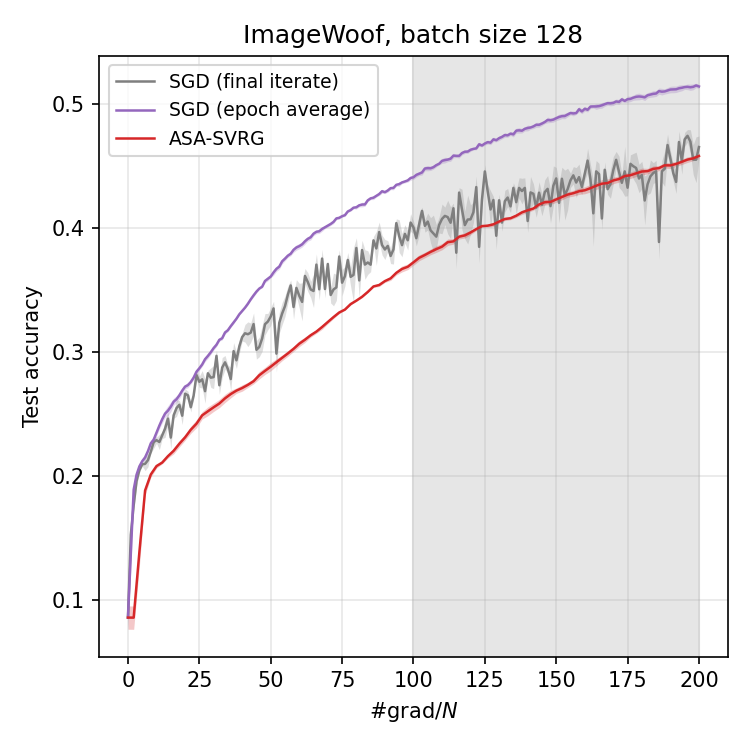

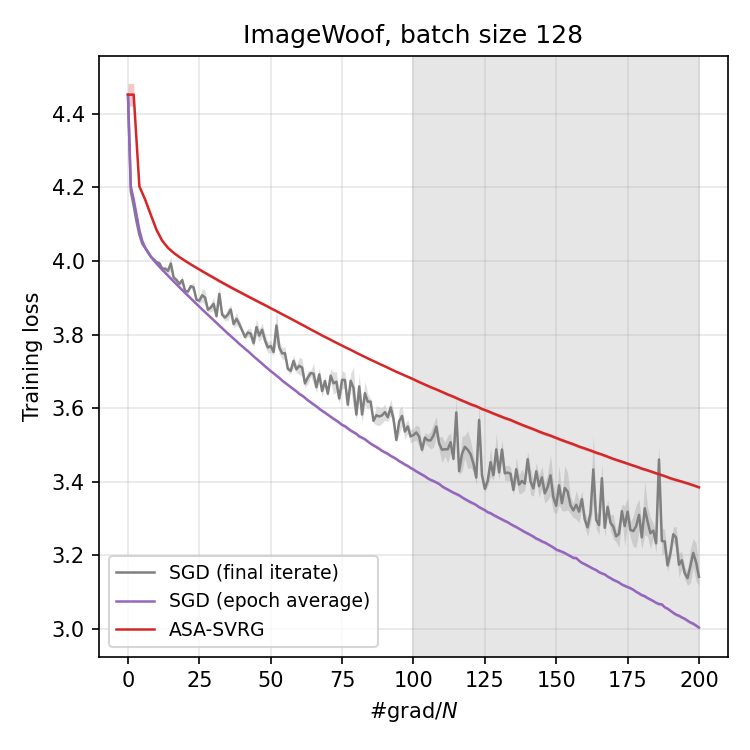

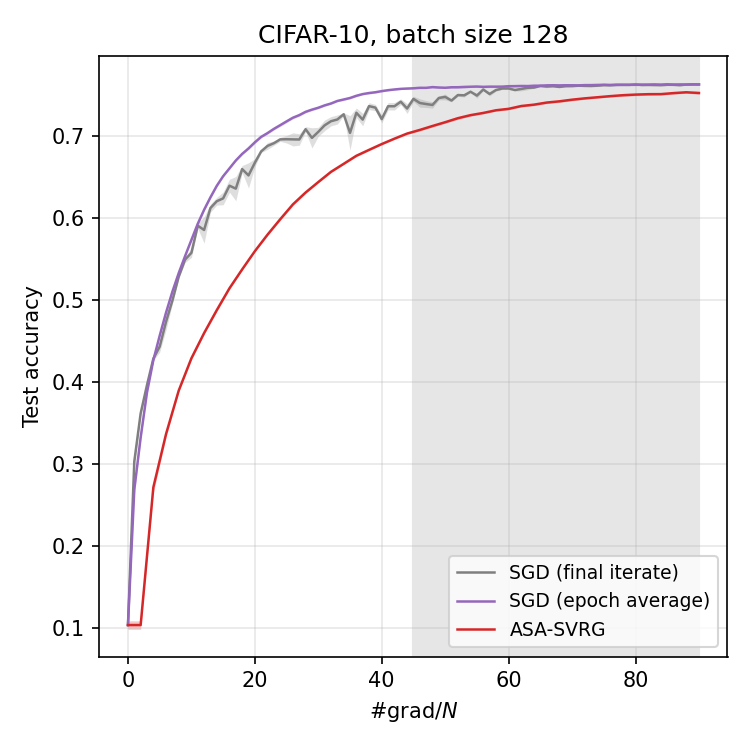

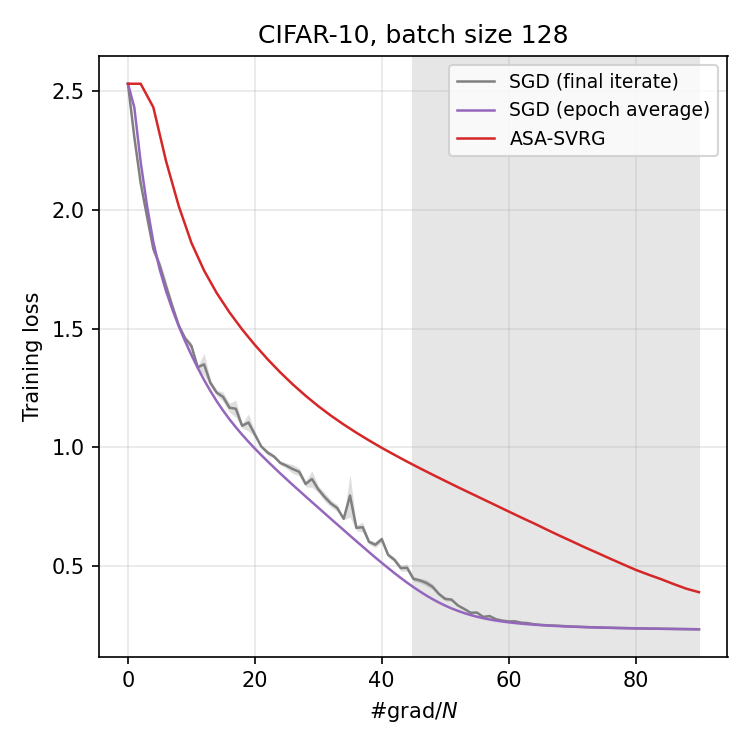

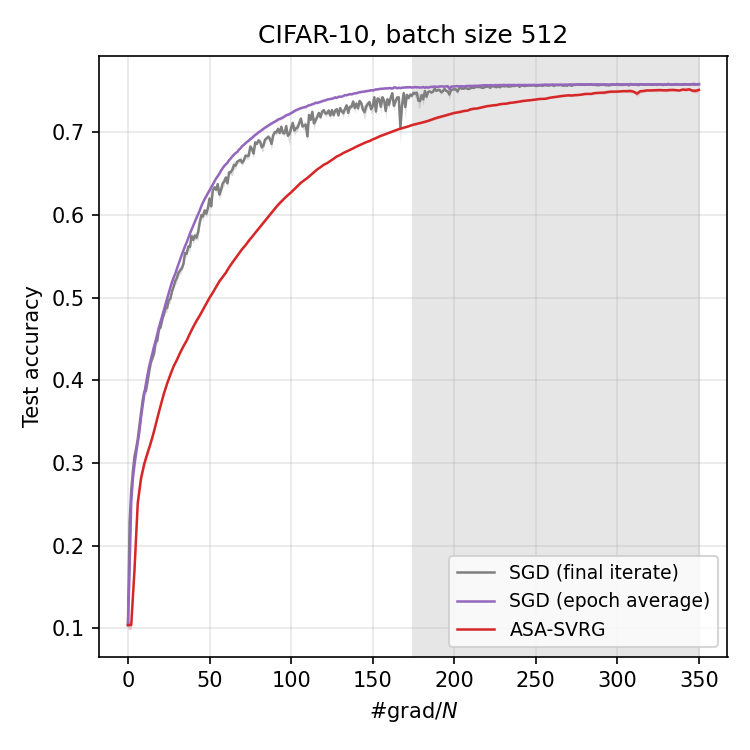

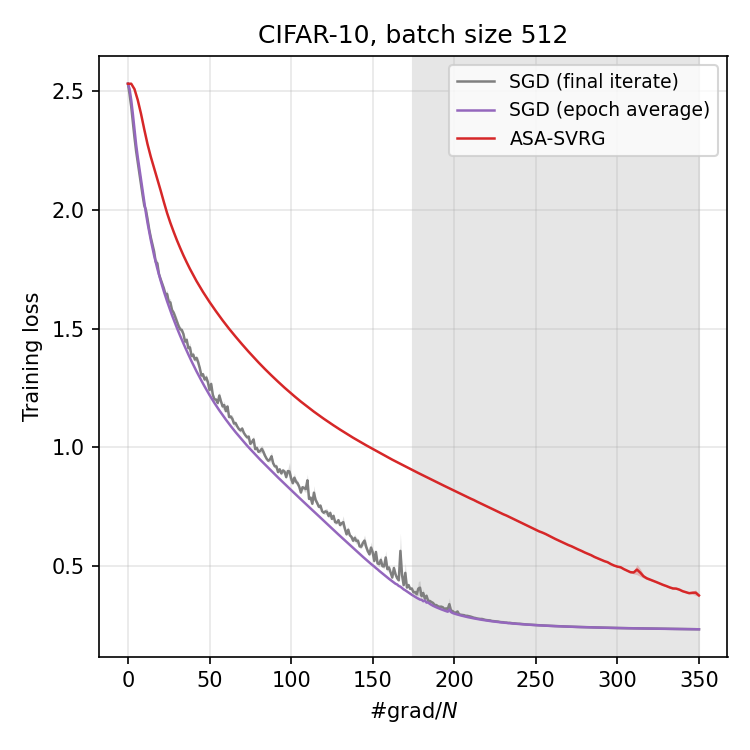

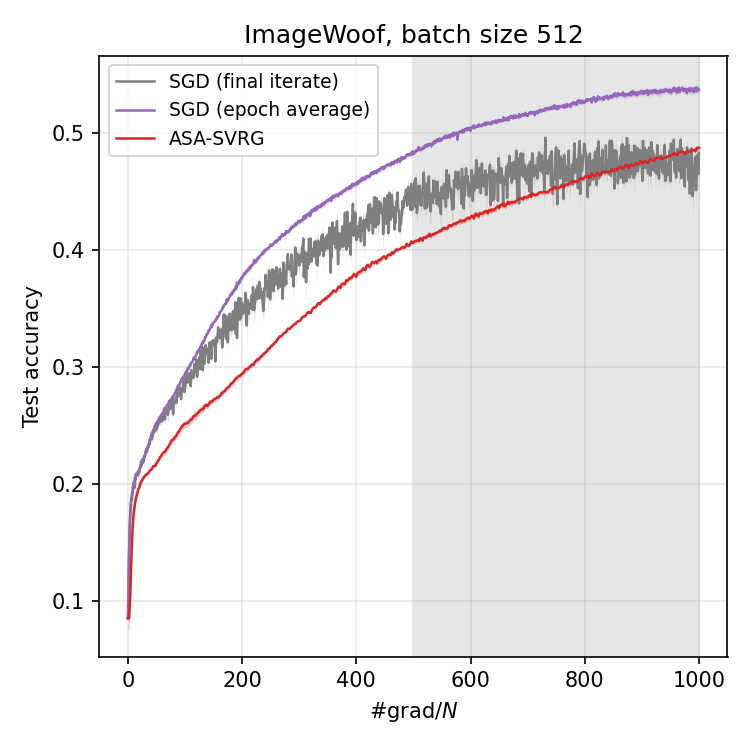

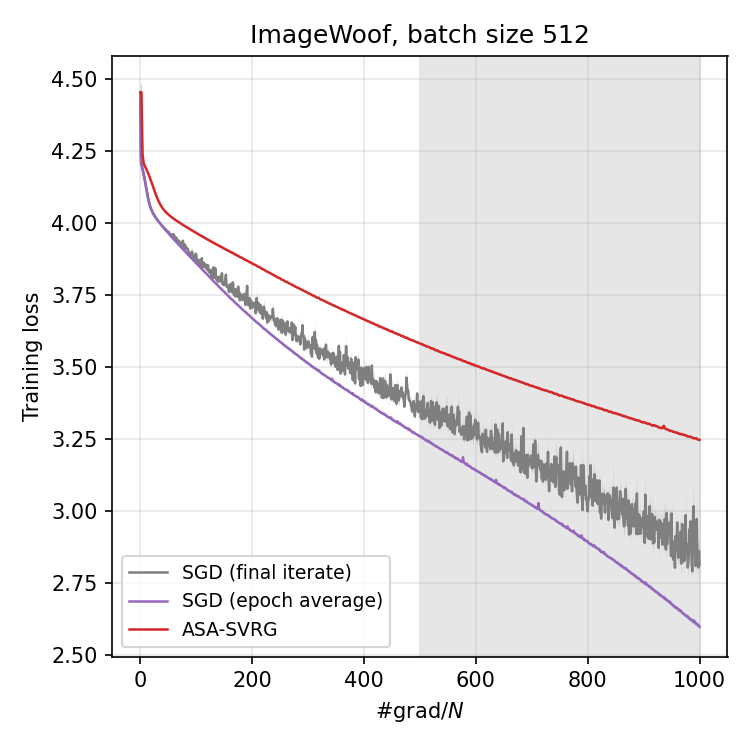

In [3]:
for dataset, batch_size in SETTINGS:
    for key in ('test_accuracy', 'train_loss'):
        path = os.path.join(a.FIGURE_DIR, f'e5_{dataset}_bs{batch_size}_{key}.png')
        if os.path.exists(path):
            display(Image(filename=path, width=420))